# Electrode-pair polarity check: mirror-symmetric fish

Fitting the model to the recordings suggested that pairs 2 and 5 are wired (or labelled) with + and − swapped in
`electrodes_signed_px_coord_2024-02-13.csv`. This notebook checks it with a symmetry argument that needs no fit, no model
and no knowledge of which EOD phase is head-positive.

**Logic.** Neighbouring pairs a and b along the tank wall have one electrode each at a shared spot (a tank corner, or the middle
of a wall). The line that mirrors pair a onto pair b runs through that spot. When the emitting fish lies on this line with
one end at the spot, the whole scene is mirror-symmetric, so the two pairs see the same potential difference up to their labels:

* the two electrodes at the spot carry the **same** label (both − or both +) → the two pair voltages have the **same** sign;
* **different** labels → **opposite** signs.

This compares two pairs within one EOD, so the unknown sign of the EOD (which phase, head- or tail-positive) cancels. A pair
with swapped wiring breaks the rule at every spot it shares with a correctly wired neighbour.

The physics model (resistive, unit head-positive current along the emitter's midline, the other fish as bodies) is used only
to illustrate the examples. It obeys the symmetry with the CSV labels by construction.

**Selection** (whole recording, the largest fish only, tracked keypoints stored in each EOD row, then the masks):
1. the largest fish has its head or tail near the spot, its head–tail axis close to the mirror line, and head, middle and tail
   all close to the line;
2. no other fish nearby: no keypoint of another fish near the spot, and (from the masks) every other fish's body at least
   `CLEAR_MIN` from the emitter's body;
3. the two pairs are the two largest of the EOD's spatial pattern (rank-1 fit of the 10 × 25 window), so the fish at the spot
   is the emitter;
4. the fish's mask lies along the line: 98% of its pixels within a narrow band around the line, and its extent along the
   line at least 85% of the fish's length. This rejects fish whose three keypoints line up but whose body curls around the
   corner.

Two recordings: 2024-02-20T21_16_26 (sections 2–3) and 2024-02-20T17_56_24 with Kaden's tracking (section 4). Both use the
electrode file of 2024-02-13.

In [1]:
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
from compute_electric_field import mask_to_grid
from eod_assign import (load_electrode_pairs, eod_sample_count, eods_with_masks, recorded_pair_traces_all,
                        recorded_pair_traces, eod_phase_samples, normalize_peak, candidate_field, pair_voltages,
                        iter_mgz_frames)
from midline_methods import fish_midline_with_head
from io_utils import rle_decode

ELECTRODES_CSV = 'data/electrodes_signed_px_coord_2024-02-13.csv'
P, FS = 912, 20000.0
N, delta_h = 200, 0.5
MAT = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=200.0, eps_interior=0.0, sigma_skin=0.05, eps_skin=2.7e-6)

pairs = load_electrode_pairs(ELECTRODES_CSV, P)
pair_ids = [pid for pid, _, _ in pairs]

def mask_under_keypoint(row, fm, k):
    '''Index of the mask nearest tracked fish k's middle keypoint in a df_eod row (the mask under it, if any).'''
    p = np.array([row[f'middle_y_{k}'], row[f'middle_x_{k}']])
    return int(np.argmin([np.min(np.linalg.norm(np.argwhere(m) - p, axis=1)) if m.any() else np.inf for m in fm]))

def load_recording(name, eod_csv, n_frames, frame_masks, mask_of=mask_under_keypoint):
    '''One recording: its EODs, their rank-1 patterns and the tracked keypoints.
       frame_masks(frames) -> {frame: (n_fish, P, P) masks}; mask_of(row, frame masks, fish id) -> index of that fish's mask.'''
    df_all = pd.read_csv(eod_csv, low_memory=False)
    df = eods_with_masks(df_all, n_frames)
    n_samp = eod_sample_count(df)
    V_all = recorded_pair_traces_all(df, pair_ids, n_samp)
    U_, s_, _ = np.linalg.svd(np.nan_to_num(V_all), full_matrices=False)
    ids = sorted(m.group(1) for c in df.columns for m in [re.match(r'middle_x_(\w+)$', c)] if m)
    kp = {k: [df[[f'{b}_y_{k}', f'{b}_x_{k}']].to_numpy(float) / (P - 1) for b in ('head', 'middle', 'tail')] for k in ids}
    lengths = {k: np.nanmedian(np.linalg.norm(kp[k][0] - kp[k][2], axis=1)) * (P - 1) for k in ids}
    R = dict(name=name, df=df, n_samp=n_samp, u=U_[:, :, 0] * s_[:, :1], ids=ids, kp=kp, lengths=lengths,
             big=max(lengths, key=lengths.get), frame_masks=frame_masks, mask_of=mask_of)
    print(f"{name}: {len(df)} EODs | variance in the rank-1 pattern: median "
          f"{np.median(s_[:, 0]**2 / np.sum(s_**2, axis=1)):.4f} | median head-tail length per tracked fish (px): "
          f"{ {k: round(v) for k, v in lengths.items()} } -> largest: {R['big']}")
    return R

## 1. Mirror lines and the shared spots

The mirror line of pairs a and b is the perpendicular bisector of the two pairs' midpoints (reflecting across it maps one pair
onto the other). For the corner pairs 2/3 (and 4/5) it runs along the tank diagonal. Pairs 5 and 6 lie on the same wall
with their − ends meeting in the middle of it, so their mirror line is perpendicular to that wall.

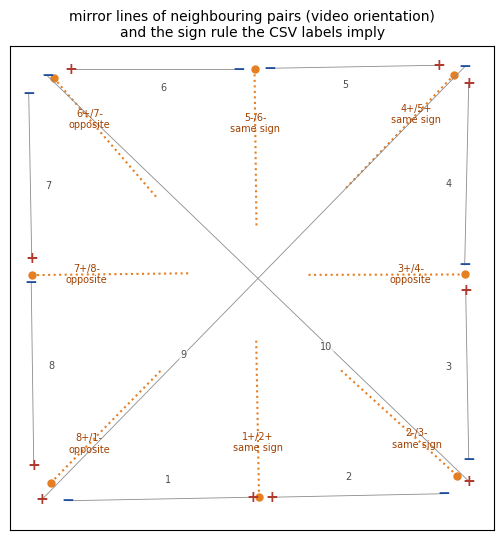

In [2]:
SPOTS = [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 1)]
ELEC = {pid: {'+': pp, '-': pm} for pid, pp, pm in pairs}

def mirror_line(pa, pb):
    '''(spot, d, labels): the point of the mirror line of pairs pa, pb next to their closest electrodes, the line's unit
       direction pointing into the tank, and the labels (of pa, of pb) of those two closest electrodes. Tank coordinates.'''
    la, lb = min(((x, y) for x in '+-' for y in '+-'), key=lambda xy: np.linalg.norm(ELEC[pa][xy[0]] - ELEC[pb][xy[1]]))
    ma, mb = 0.5 * (ELEC[pa]['+'] + ELEC[pa]['-']), 0.5 * (ELEC[pb]['+'] + ELEC[pb]['-'])
    n = (mb - ma) / np.linalg.norm(mb - ma)
    d = np.array([-n[1], n[0]]); c = 0.5 * (ma + mb)
    spot = c + ((0.5 * (ELEC[pa][la] + ELEC[pb][lb]) - c) @ d) * d
    if (0.5 - spot) @ d < 0: d = -d
    return spot, d, (la, lb)

def draw_electrodes(ax, highlight=(), colors=None):
    '''Electrodes in video orientation (x = pixel column, y = pixel row downwards).'''
    for q, pp, pm in pairs:
        hl = q in highlight; c = (colors or {}).get(q, 'm')
        ax.plot([pp[1], pm[1]], [pp[0], pm[0]], color=c if hl else '0.55', lw=2.2 if hl else 0.6, zorder=3)
        ax.text(pp[1], pp[0], '+', color='#B03A2E', fontsize=15 if hl else 11, weight='bold', ha='center', va='center', zorder=4)
        ax.text(pm[1], pm[0], '−', color='#1F4E9A', fontsize=15 if hl else 11, weight='bold', ha='center', va='center', zorder=4)
        mid = 0.5 * (pp + pm) if np.linalg.norm(pp - pm) < 1 else pp + 0.3 * (pm - pp)
        lab = mid + 0.045 * (0.5 - mid) / max(np.linalg.norm(0.5 - mid), 1e-9)
        ax.text(lab[1], lab[0], str(q), zorder=6, bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.7),
                fontsize=10 if hl else 7, color=c if hl else '0.3', weight='bold' if hl else 'normal', ha='center', va='center')
    ax.set(xlim=(-0.03, 1.03), ylim=(1.03, -0.03), aspect='equal', xticks=[], yticks=[])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
draw_electrodes(ax)
for pa, pb in SPOTS:
    spot, d, (la, lb) = mirror_line(pa, pb)
    end = spot + 0.35 * d
    ax.plot([spot[1], end[1]], [spot[0], end[0]], ':', color='#E67E22', lw=1.5)
    ax.plot(spot[1], spot[0], 'o', color='#E67E22', ms=5)
    t = spot + 0.12 * d
    ax.text(t[1], t[0], f'{pa}{la}/{pb}{lb}\n' + ('same sign' if la == lb else 'opposite'), fontsize=7, ha='center',
            va='center', color='#A04000')
ax.set_title('mirror lines of neighbouring pairs (video orientation)\nand the sign rule the CSV labels imply', fontsize=10)
plt.tight_layout(); plt.show()

### The search and the plots

Thresholds, in tank units (1 = 911 px): the fish's end within 0.18 of the spot, axis within 30° of the line, keypoints within
0.06 of it, other fish at least 0.2 away; then the mask: 98th percentile of the pixels' distance from the line ≤ `BAND_MAX`,
extent along the line ≥ `EXTENT_MIN` × the fish's median head–tail length, and every other fish's mask at least `CLEAR_MIN`
from the emitter's mask. Only the frames that pass the keypoint step are
read from the masks.

Examples: two frames per spot, both of the largest fish, from two separate visits to the spot (at least 100 frames apart),
favouring the EODs with the other fish farthest away (score: band + distance of the fish's end from the spot + angle to the
line − distance to the nearest other fish). The 5/6 spot is busy: there the nearest other fish is never much more than 100–
160 px away. Each row:
the model potential with the fish (video orientation, emitter outlined thick), the recorded traces of all 10 pairs, and model
vs recording at the EOD's first phase P1, each scaled to max |v| = 1. No sign is changed anywhere.

In [3]:
BAND_MAX, EXTENT_MIN, CLEAR_MIN = 0.05, 0.85, 0.10      # CLEAR_MIN: 91 px, about half the largest fish
EV_COLS = ['pa', 'pb', 'row', 'frame', 'k', 'end', 'dist_end', 'angle', 'offset', 'other', 'u_a', 'u_b', 'same_sign', 'rule_same']
PAIR_COLORS = ('m', '#16A085')
g = np.linspace(0, 1, N)

def symmetric_events(R, pa, pb, max_end=0.18, max_angle=30.0, max_offset=0.06, min_other=0.2):
    '''EODs of recording R passing selection steps 1-3 for the spot of pairs pa, pb, with the largest fish at the spot.'''
    df, u, kp, k = R['df'], R['u'], R['kp'], R['big']
    spot, d, (la, lb) = mirror_line(pa, pb); nrm = np.array([-d[1], d[0]])
    ia, ib = pair_ids.index(pa), pair_ids.index(pb)
    top2 = np.sort(np.argsort(-np.abs(u), axis=1)[:, :2], axis=1)
    is_top = (top2 == sorted((ia, ib))).all(axis=1)
    H, Mid, T = kp[k]
    dH, dT = np.linalg.norm(H - spot, axis=1), np.linalg.norm(T - spot, axis=1)
    head_in = dH < dT
    E, O = np.where(head_in[:, None], H, T), np.where(head_in[:, None], T, H)
    axis = (O - E) / np.linalg.norm(O - E, axis=1, keepdims=True)
    angle = np.degrees(np.arccos(np.clip(axis @ d, -1, 1)))
    offset = np.max([np.abs((q - spot) @ nrm) for q in (H, Mid, T)], axis=0)
    other = np.nanmin([np.linalg.norm(q - spot, axis=1) for j in R['ids'] if j != k for q in kp[j]], axis=0)
    with np.errstate(invalid='ignore'):
        ok = is_top & (np.minimum(dH, dT) < max_end) & (angle < max_angle) & (offset < max_offset) & (other > min_other)
    return pd.DataFrame([dict(pa=pa, pb=pb, row=df.index[i], frame=int(df['Frame'].iloc[i]), k=k,
                              end='head' if head_in[i] else 'tail', dist_end=min(dH[i], dT[i]), angle=angle[i],
                              offset=offset[i], other=other[i], u_a=u[i, ia], u_b=u[i, ib],
                              same_sign=bool(np.sign(u[i, ia]) == np.sign(u[i, ib])), rule_same=la == lb)
                         for i in np.flatnonzero(ok)], columns=EV_COLS)

def along_line(mask, spot, d):
    '''(band, extent) of a mask relative to the line (spot, d): 98th percentile of its pixels' distance from the line, and
       its extent along the line (1st to 99th percentile). Tank units.'''
    q = np.argwhere(mask) / (P - 1) - spot
    s = q @ d
    return np.percentile(np.abs(q @ np.array([-d[1], d[0]])), 98), np.percentile(s, 99) - np.percentile(s, 1)

def mirror_events(R):
    '''All spots: keypoint steps, then the mask step. Returns (all keypoint-step events, events passing the mask step).'''
    ev = pd.concat([symmetric_events(R, pa, pb) for pa, pb in SPOTS], ignore_index=True)
    ev = ev.reindex(columns=EV_COLS + ['mask', 'band', 'extent', 'largest', 'clearance', 'follows_labels'])
    if ev.empty: return ev, ev
    band, extent, largest, mask, clear = {}, {}, {}, {}, {}
    for fr, fm in R['frame_masks'](set(ev.frame)).items():
        for i in ev.index[ev.frame == fr]:
            f = mask[i] = R['mask_of'](R['df'].loc[int(ev.at[i, 'row'])], fm, R['big'])
            spot, d, _ = mirror_line(int(ev.at[i, 'pa']), int(ev.at[i, 'pb']))
            largest[i] = f == int(np.argmax([m.sum() for m in fm]))
            band[i], extent[i] = along_line(fm[f], spot, d) if fm[f].any() else (np.nan, np.nan)
            extent[i] /= R['lengths'][R['big']] / (P - 1)
            dt = distance_transform_edt(~fm[f])
            clear[i] = min((dt[m].min() for j, m in enumerate(fm) if j != f and m.any()), default=np.inf) / (P - 1)
    ev['mask'], ev['band'], ev['extent'], ev['largest'] = pd.Series(mask), pd.Series(band), pd.Series(extent), pd.Series(largest)
    ev['clearance'] = pd.Series(clear)
    ev['follows_labels'] = ev.same_sign == ev.rule_same
    return ev, ev[(ev.band <= BAND_MAX) & (ev.extent >= EXTENT_MIN) & (ev.clearance >= CLEAR_MIN)]

def spot_table(E):
    idx = pd.MultiIndex.from_tuples(SPOTS, names=['pa', 'pb'])
    lab = {s: mirror_line(*s)[2] for s in SPOTS}
    t = pd.DataFrame({'labels at spot': [f'{a}{lab[(a, b)][0]} / {b}{lab[(a, b)][1]}' for a, b in SPOTS],
                      'rule': ['same sign' if lab[s][0] == lab[s][1] else 'opposite' for s in SPOTS]}, index=idx)
    g_ = E.groupby(['pa', 'pb']) if len(E) else None
    t['EODs'] = (g_.size().reindex(idx) if g_ else pd.Series(0, idx)).fillna(0).astype(int)
    t['visits (>100 frames apart)'] = (g_.frame.apply(lambda f: int((np.diff(np.sort(f.to_numpy())) > 100).sum() + 1))
                                       .reindex(idx) if g_ else pd.Series(0, idx)).fillna(0).astype(int)
    t['follow labels'] = (g_.follows_labels.mean().reindex(idx) if g_ else pd.Series(np.nan, idx)).round(2)
    t['verdict'] = ['no symmetric fish' if n == 0 else ('labels hold' if m >= 0.9 else
                    ('labels CONTRADICTED' if m <= 0.1 else 'mixed')) for n, m in zip(t.EODs, t['follow labels'])]
    return t

def pick_examples(sym, pa, pb, n=2, min_gap=100):
    E = sym[(sym.pa == pa) & (sym.pb == pb)].assign(score=lambda x: x.band + x.dist_end + x.angle / 100 - x.clearance)
    out = []
    for _, e in E.sort_values('score').iterrows():
        if len(out) == n: break
        if all(abs(e.frame - o.frame) > min_gap for o in out): out.append(e)
    return out

def head_agrees(row, k, mid):
    '''Whether the midline's head end is nearer the row's head keypoint of fish k than its tail end is.'''
    hd = np.array([row[f'head_y_{k}'], row[f'head_x_{k}']]) / (P - 1)
    tl = np.array([row[f'tail_y_{k}'], row[f'tail_x_{k}']]) / (P - 1)
    return bool(np.linalg.norm(mid[-1] - hd) + np.linalg.norm(mid[0] - tl) < np.linalg.norm(mid[-1] - tl) + np.linalg.norm(mid[0] - hd))

def plot_example(axes, R, e, fm):
    pa, pb = int(e.pa), int(e.pb); r = int(e.row); row = R['df'].loc[r]
    f = int(e['mask']); colors = dict(zip((pa, pb), PAIR_COLORS))
    mids = [fish_midline_with_head(m, n_ctrl=101)['midline'] if m.sum() >= 50 else None for m in fm]
    phi = candidate_field(fm, f, mids[f], N, delta_h, MAT).real
    a = normalize_peak(pair_voltages(phi, pairs, N))
    V = recorded_pair_traces(row, pair_ids, R['n_samp'])
    p1, p2 = eod_phase_samples(V)
    b = normalize_peak(V[:, p1])
    ia, ib = pair_ids.index(pa), pair_ids.index(pb)
    spot, d, _ = mirror_line(pa, pb)
    t_ms = np.arange(R['n_samp']) / FS * 1e3

    ax = axes[0]
    vmax = np.percentile(np.abs(phi), 99)
    ax.imshow(phi, origin='upper', extent=[0, 1, 1, 0], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for j, m in enumerate(fm):
        if m.any():
            ax.contour(g, g, mask_to_grid(m, N).astype(float), levels=[0.5], colors=['k' if j == f else '0.35'],
                       linewidths=2.0 if j == f else 0.8)
    ax.plot(mids[f][-1][1], mids[f][-1][0], 'o', color='gold', ms=7, mec='k', mew=0.8, zorder=5, label='head')
    ax.plot(mids[f][0][1], mids[f][0][0], 's', color='w', ms=6, mec='k', mew=0.8, zorder=5, label='tail')
    end = spot + 0.45 * d
    ax.plot([spot[1], end[1]], [spot[0], end[0]], ':', color='k', lw=1, zorder=3, label=f'{pa}/{pb} mirror line')
    draw_electrodes(ax, (pa, pb), colors)
    big = 'largest fish' if e.largest else 'largest fish (not the largest mask in this frame)'
    ax.set_title(f'frame {int(e.frame)}: {big} ({R["big"]}), {e.end} at the {pa}/{pb} spot\n'
                 f'body within {e.band * (P - 1):.0f} px of the line, nearest other fish {e.clearance * (P - 1):.0f} px; '
                 f'model, head-positive current', fontsize=9)
    ax.legend(loc='center', fontsize=7, framealpha=0.8)

    ax = axes[1]
    for i, q in enumerate(pair_ids):
        hl = q in colors
        ax.plot(t_ms, V[i] / np.max(np.abs(V)), color=colors.get(q, '0.75'), lw=2.2 if hl else 0.9,
                label=f'pair {q}' if hl else ('other pairs' if i == 0 else None), zorder=3 if hl else 2)
    for p, lab in ((p1, 'P1'), (p2, 'P2')):
        ax.axvline(t_ms[p], color='k', ls='--' if lab == 'P1' else ':', lw=0.8); ax.text(t_ms[p], 1.08, lab, ha='center', fontsize=9)
    ax.axhline(0, color='0.85', lw=0.5)
    ax.set(xlabel='time (ms)', ylabel='recorded voltage (max |V| = 1)', ylim=(-1.15, 1.2), title=f'recorded EOD (df_eod row {r})')
    ax.legend(fontsize=8, loc='lower left')

    ax = axes[2]
    x = np.arange(len(pair_ids)); w = 0.38
    ax.bar(x - w / 2, b, w, color='k', label=f'recorded at P1 (t = {t_ms[p1]:.2f} ms)')
    ax.bar(x + w / 2, a, w, color='#E67E22', label='model (head-positive current)')
    for q, c in colors.items():
        ax.axvspan(pair_ids.index(q) - 0.5, pair_ids.index(q) + 0.5, color=c, alpha=0.12, zorder=0)
    ax.axhline(0, color='k', lw=0.5)
    ax.set(xticks=x, xticklabels=pair_ids, xlabel='electrode pair', ylabel='voltage (max |v| = 1)', ylim=(-1.25, 1.25),
           title=f'pairs {pa} / {pb}: recorded {b[ia]:+.2f} / {b[ib]:+.2f},  model {a[ia]:+.2f} / {a[ib]:+.2f}')
    ax.legend(fontsize=8, loc='lower left')
    return dict(recording=R['name'], row=r, frame=int(e.frame), pairs=f'{pa}/{pb}', fish=R['big'], end=e.end,
                head_matches_keypoints=head_agrees(row, R['big'], mids[f]),
                rec_a=round(b[ia], 2), rec_b=round(b[ib], 2), model_a=round(a[ia], 2), model_b=round(a[ib], 2))

def show_spot(R, sym, pa, pb, title):
    ex = pick_examples(sym, pa, pb)
    if not ex:
        print(f'{R["name"]}, pairs {pa}/{pb}: no symmetric EOD of the largest fish'); return []
    fms = R['frame_masks']({int(e.frame) for e in ex})
    fig, axes = plt.subplots(len(ex), 3, figsize=(17, 5.6 * len(ex)), squeeze=False,
                             gridspec_kw=dict(width_ratios=[1, 1.1, 1.3]))
    out = [plot_example(ax_row, R, e, fms[int(e.frame)]) for e, ax_row in zip(ex, axes)]
    fig.suptitle(f'{R["name"]}: {title} (largest fish, {len(ex)} visit{"s" if len(ex) > 1 else ""})', fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()
    return out

TITLE_23 = 'fish on the 2/3 mirror line (tank diagonal): 2− and 3− share the corner, so pairs 2 and 3 must have the same sign'
TITLE_56 = 'fish on the 5/6 mirror line (perpendicular to the wall): 5− and 6− meet mid-wall, so pairs 5 and 6 must have the same sign'
shown = []

## 2. Recording 2024-02-20T21_16_26: symmetric EODs at every spot

In [4]:
MGZ = 'data/video2024-02-20T21_16_26__223e__59997__masks_packed.mgz'
R1 = load_recording('2024-02-20T21_16_26', 'data/Data_4fish_2024-02-20T21_16_26.csv', 60000,
                    lambda frames: dict(iter_mgz_frames(MGZ, frames)))
ev1, sym1 = mirror_events(R1)
print(f"{len(ev1)} EODs after the keypoint steps, {len(sym1)} after the mask step")
spot_table(sym1)

2024-02-20T21_16_26: 54537 EODs | variance in the rank-1 pattern: median 0.9988 | median head-tail length per tracked fish (px): {'1': 176, '2': 160, '3': 117, '4': 100} -> largest: 1


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_84856/1218731291.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ev = pd.concat([symmetric_events(R, pa, pb) for pa, pb in SPOTS], ignore_index=True)


479 EODs after the keypoint steps, 70 after the mask step


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,24,2,0.0,labels CONTRADICTED
3,4,3+ / 4-,opposite,0,0,NaN,no symmetric fish
4,5,4+ / 5+,same sign,5,1,0.0,labels CONTRADICTED
5,6,5- / 6-,same sign,7,3,0.0,labels CONTRADICTED
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,34,3,1.0,labels hold
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


In [5]:
print('the same table without the mask step (keypoints only):')
spot_table(ev1)

the same table without the mask step (keypoints only):


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,24,2,0.00,labels CONTRADICTED
3,4,3+ / 4-,opposite,0,0,NaN,no symmetric fish
4,5,4+ / 5+,same sign,14,3,0.07,labels CONTRADICTED
5,6,5- / 6-,same sign,350,23,0.00,labels CONTRADICTED
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,91,6,1.00,labels hold
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


## 3. Recording 2024-02-20T21_16_26: examples, with the model

### Pairs 2 and 3 (corner, both − ends): symmetry requires the same sign

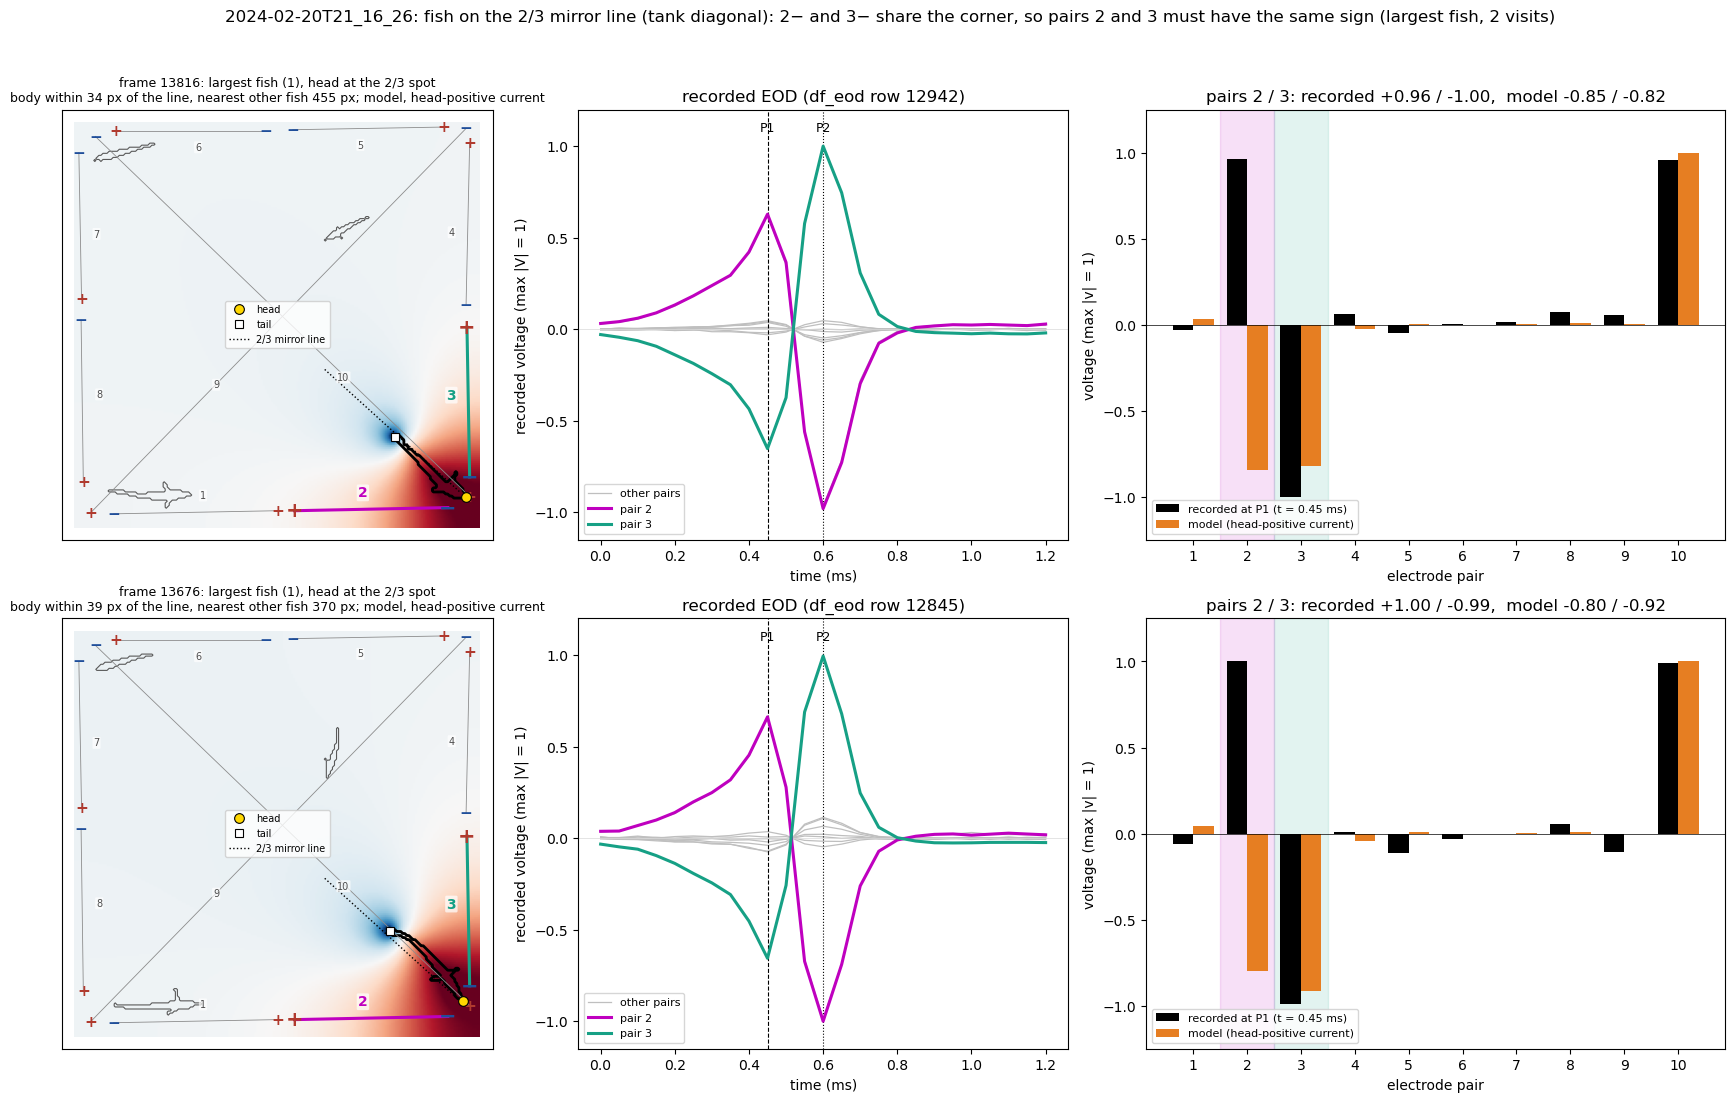

In [6]:
shown += show_spot(R1, sym1, 2, 3, TITLE_23)

### Pairs 5 and 6 (middle of the wall, both − ends): symmetry requires the same sign

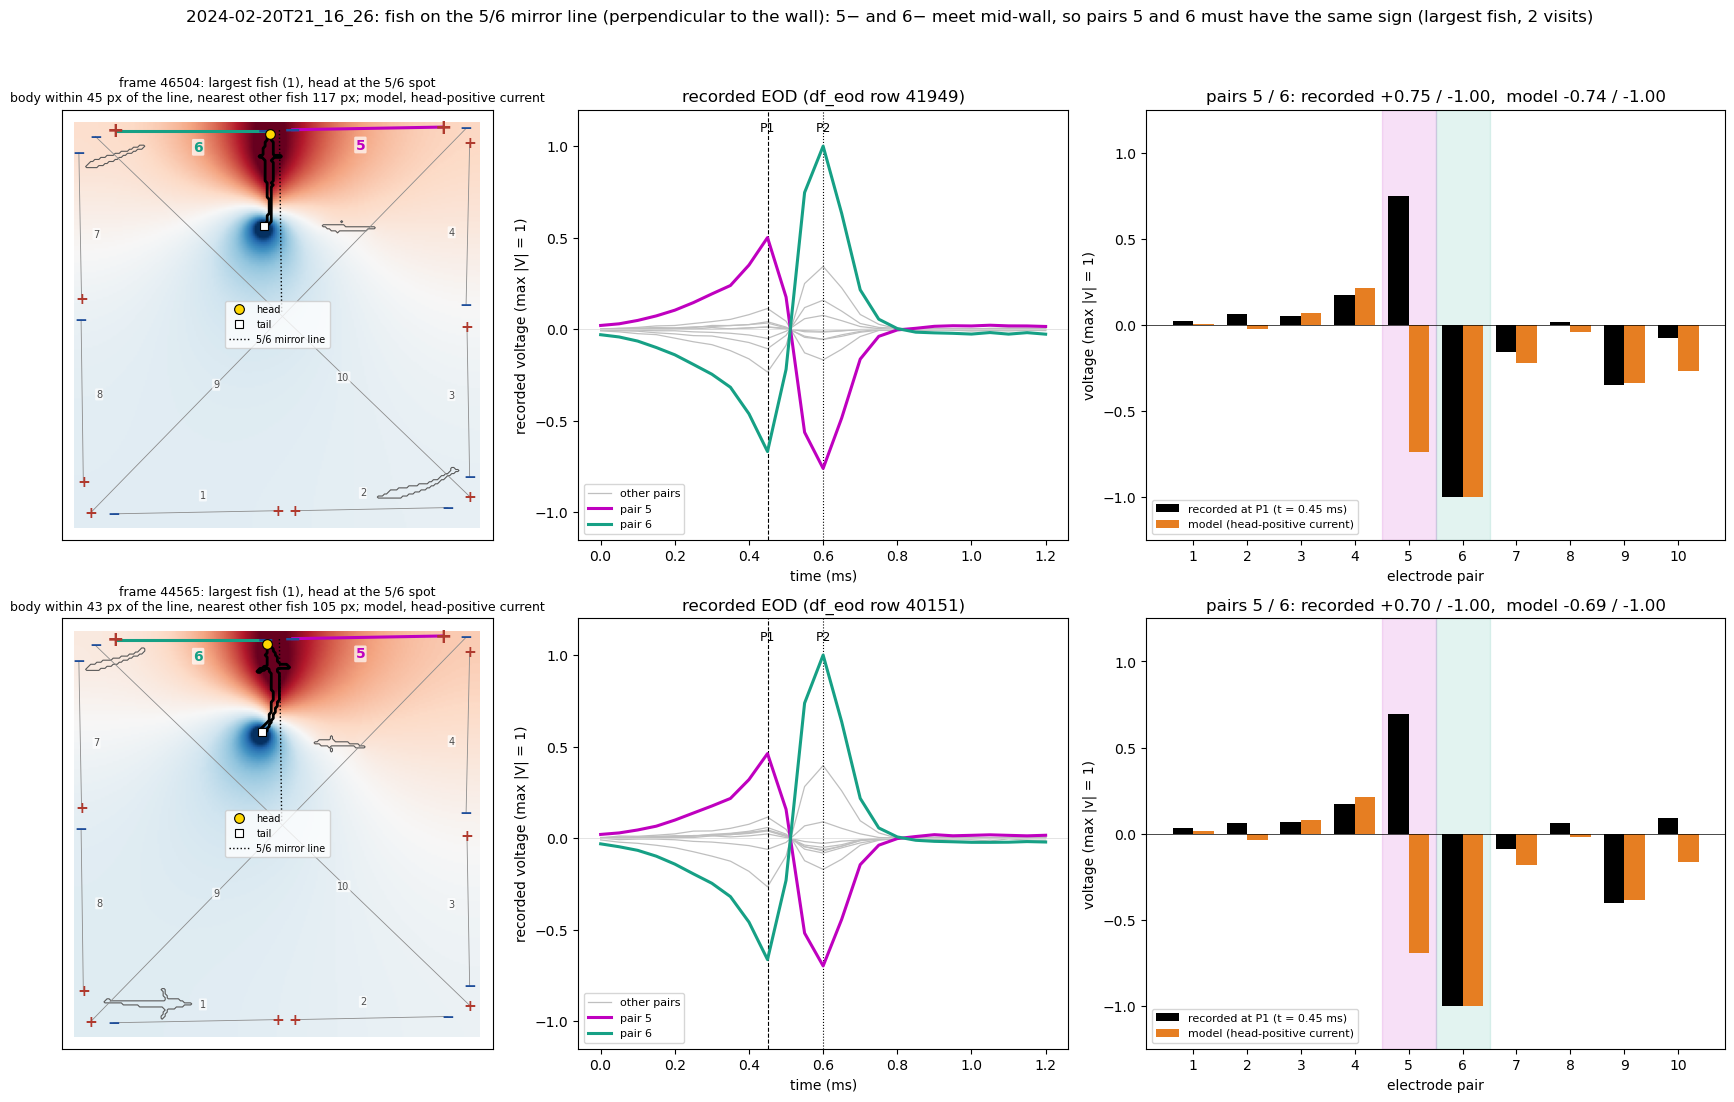

In [7]:
shown += show_spot(R1, sym1, 5, 6, TITLE_56)

## 4. Recording 2024-02-20T17_56_24 (Kaden's tracking)

Of the 14 recordings with Kaden's tracking (12_32_58 to 18_36_24), this is the only one in which the largest fish (A) reaches
the 2/3 corner on the mirror line; in all of them it visits the 5/6 spot. Masks: `mask_visible` of
`data/track_Kaden/results_17_56_24_full/.../video2024-02-20T17_56_24.pkl` (fish A–D = mask 0–3). EODs and keypoints:
`data/Denis Assignment/with Kaden Tracking/Data_4fish_2024-02-20T17_56_24_no_ref_per.csv`. Its `Frame` indexes the tracking
frames directly: the keypoints in each row are Kaden's midline keypoints of that frame. Same electrode file, same selection,
same thresholds.

In [8]:
KADEN_PKL = 'data/track_Kaden/results_17_56_24_full/video2024-02-20T17_56_24/outputs/video2024-02-20T17_56_24.pkl'
K = pickle.load(open(KADEN_PKL, 'rb'))
assert tuple(K['image_size']) == (P, P)

def kaden_frame_masks(frames):
    return {fr: np.stack([np.zeros((P, P), bool) if rle is None else rle_decode(rle) for rle in K['mask_visible'][fr]])
            for fr in sorted(frames)}

R2 = load_recording('2024-02-20T17_56_24', 'data/Denis Assignment/with Kaden Tracking/Data_4fish_2024-02-20T17_56_24_no_ref_per.csv',
                    K['n_frames'], kaden_frame_masks, mask_of=lambda row, fm, k: K['letters'].index(k))
row = R2['df'].iloc[len(R2['df']) // 2]; fr = int(row.Frame)
print('check, keypoints vs Kaden midline (px) in one row:',
      round(float(np.linalg.norm(K['midline'][fr, 0, 2] - [row.middle_x_A, row.middle_y_A])), 4))
ev2, sym2 = mirror_events(R2)
print(f"{len(ev2)} EODs after the keypoint steps, {len(sym2)} after the mask step")
spot_table(sym2)

2024-02-20T17_56_24: 70955 EODs | variance in the rank-1 pattern: median 0.9988 | median head-tail length per tracked fish (px): {'A': 149, 'B': 135, 'C': 98, 'D': 81} -> largest: A
check, keypoints vs Kaden midline (px) in one row: 0.0006


751 EODs after the keypoint steps, 102 after the mask step


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,0,0,NaN,no symmetric fish
2,3,2- / 3-,same sign,35,2,0.0,labels CONTRADICTED
3,4,3+ / 4-,opposite,13,2,1.0,labels hold
4,5,4+ / 5+,same sign,0,0,NaN,no symmetric fish
5,6,5- / 6-,same sign,17,3,0.0,labels CONTRADICTED
6,7,6+ / 7-,opposite,0,0,NaN,no symmetric fish
7,8,7+ / 8-,opposite,37,1,1.0,labels hold
8,1,8+ / 1-,opposite,0,0,NaN,no symmetric fish


In [9]:
print('the same table without the mask step (keypoints only):')
spot_table(ev2)

the same table without the mask step (keypoints only):


,,labels at spot,rule,EODs,visits (>100 frames apart),follow labels,verdict
pa,pb,,,,,,
1,2,1+ / 2+,same sign,5,1,0.20,mixed
2,3,2- / 3-,same sign,54,5,0.07,labels CONTRADICTED
3,4,3+ / 4-,opposite,78,7,1.00,labels hold
4,5,4+ / 5+,same sign,2,2,0.50,mixed
5,6,5- / 6-,same sign,519,21,0.00,labels CONTRADICTED
6,7,6+ / 7-,opposite,2,1,0.00,labels CONTRADICTED
7,8,7+ / 8-,opposite,90,5,1.00,labels hold
8,1,8+ / 1-,opposite,1,1,0.00,labels CONTRADICTED


### Pairs 2 and 3

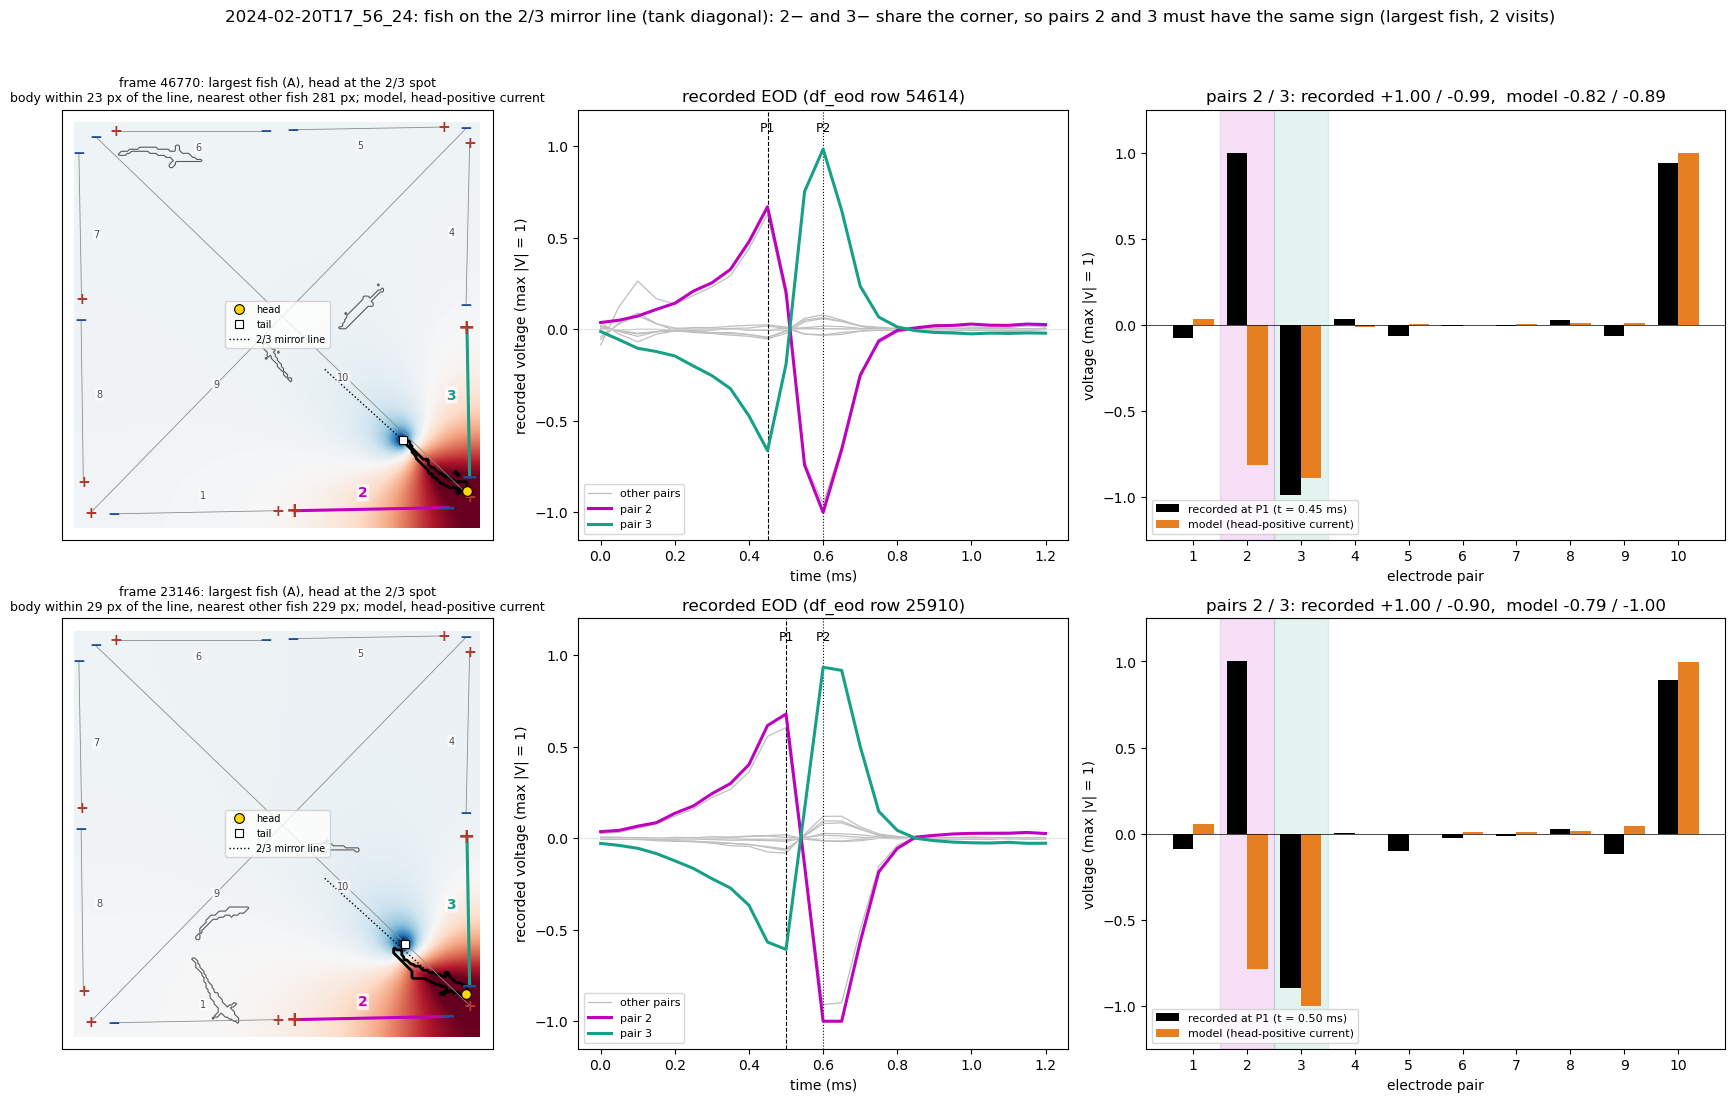

In [10]:
shown += show_spot(R2, sym2, 2, 3, TITLE_23)

### Pairs 5 and 6

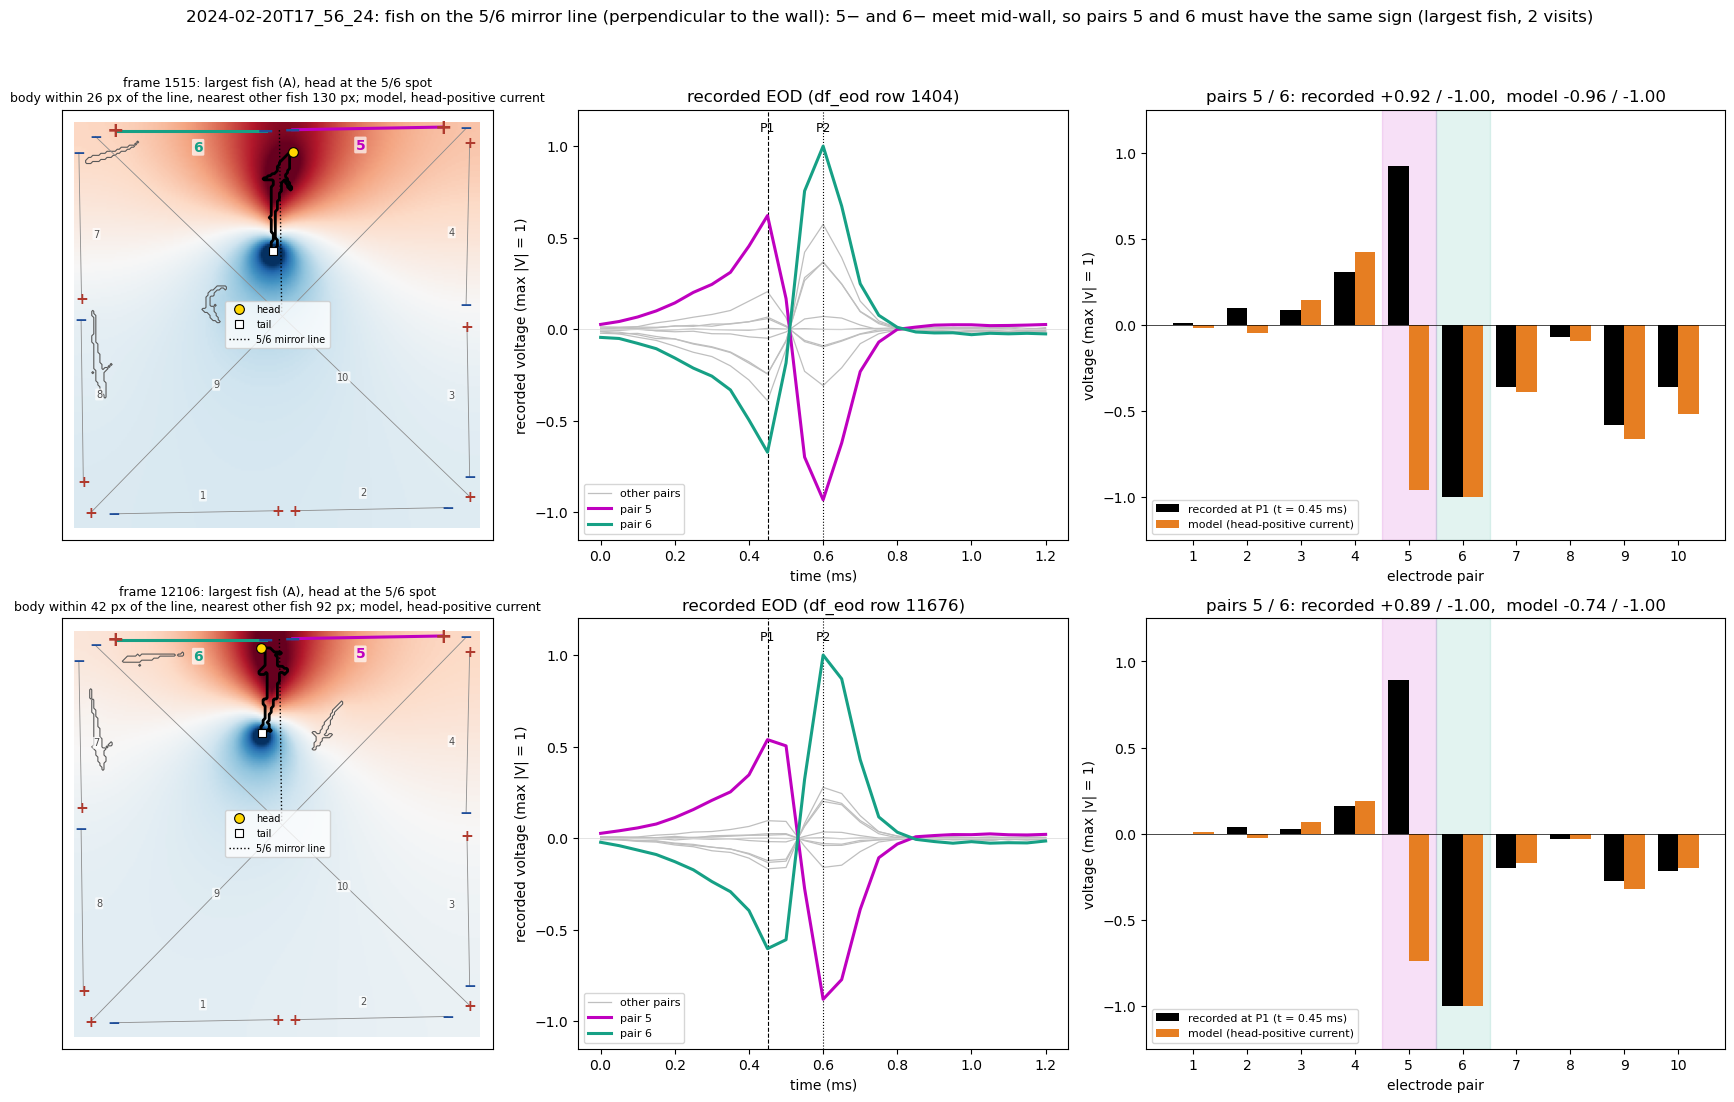

In [11]:
shown += show_spot(R2, sym2, 5, 6, TITLE_56)

## 5. All example frames

In [12]:
pd.DataFrame(shown)

,recording,row,frame,pairs,fish,end,head_matches_keypoints,rec_a,rec_b,model_a,model_b
0,2024-02-20T21_16_26,12942,13816,2/3,1,head,True,0.96,-1.00,-0.85,-0.82
1,2024-02-20T21_16_26,12845,13676,2/3,1,head,True,1.00,-0.99,-0.80,-0.92
2,2024-02-20T21_16_26,41949,46504,5/6,1,head,True,0.75,-1.00,-0.74,-1.00
3,2024-02-20T21_16_26,40151,44565,5/6,1,head,True,0.70,-1.00,-0.69,-1.00
4,2024-02-20T17_56_24,54614,46770,2/3,A,head,True,1.00,-0.99,-0.82,-0.89
5,2024-02-20T17_56_24,25910,23146,2/3,A,head,True,1.00,-0.90,-0.79,-1.00
6,2024-02-20T17_56_24,1404,1515,5/6,A,head,True,0.92,-1.00,-0.96,-1.00
7,2024-02-20T17_56_24,11676,12106,5/6,A,head,True,0.89,-1.00,-0.74,-1.00


## 6. Conclusion

**Pairs 2 and 5 are reversed relative to `electrodes_signed_px_coord_2024-02-13.csv`, in both recordings.**

Symmetric EODs of the largest fish with every other fish at least 91 px from its body:

| recording | 2/3 (needs same sign) | 5/6 (needs same sign) | 4/5 (needs same sign) | controls 3/4, 7/8 (need opposite) |
|---|---|---|---|---|
| 21_16_26 | 24 EODs, all opposite | 7, all opposite | 5, all opposite | 7/8: 34, all opposite |
| 17_56_24 (Kaden) | 35, all opposite | 17, all opposite | – | 3/4: 13 and 7/8: 37, all opposite |

* At every spot shared with pair 2 or pair 5, the two pair voltages have the opposite sign to what the labels (and the model,
  which uses them) require. At the control spots, where neither pair is involved, the labels hold in every EOD, so the test
  itself works.
* One reversed pair explains each contradiction: pair 2 for 2/3, pair 5 for 4/5 and 5/6.
* In the eight example frames the model and the recording agree on the other pairs and differ only on pair 2 or pair 5.

Nothing is fitted, and the recorded signs are never changed.